<a href="https://colab.research.google.com/github/simalyucel/clip-bias-mitigation/blob/main/notebooks/02_baseline_fairface.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 · Baseline v1: CLIP bias on FairFace (gender, race, age)

Pretrained CLIP ViT-B/32, **no mitigation**. For every query we rank the whole FairFace
validation split (~10.9k faces) and measure how the top-k is distributed over gender,
race and age.

**What is where:** the logic lives in the repo (`src/vlbias/`), this notebook only runs it
and looks at the results. Every setting comes from `configs/experiments/baseline_fairface.yaml`.

**Colab:** Runtime → Change runtime type → **T4 GPU**. A full run takes a few minutes, mostly
downloading FairFace and encoding the images once.

## 0. Setup

Clones your repo and installs it. If the repo is **private**, add a GitHub token as a Colab
secret first: key icon in the left sidebar → *Add new secret* → name `GITHUB_TOKEN`, value
= your token → toggle *Notebook access* on.

In [2]:
import os, sys

REPO = "simalyucel/clip-bias-mitigation"
ROOT = "/content/clip-bias-mitigation"

try:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")      # only needed for a private repo
except Exception:
    token = None
url = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"

if not os.path.exists(ROOT):
    !git clone -q {url} {ROOT}
else:
    !git -C {ROOT} pull -q
%cd {ROOT}
!pip -q install open_clip_torch datasets
!pip -q install -e .
sys.path.insert(0, f"{ROOT}/src")

/content/clip-bias-mitigation
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for vlbias (pyproject.toml) ... done


In [2]:
# the unit tests should all pass before trusting any number
!python -m pytest -q

....................                                                     [100%]
20 passed in 1.40s


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path

from vlbias.utils.config import load_yaml, set_seed
from vlbias.models.load import load_model
from vlbias.data.queries import load_queries
from vlbias.data.fairface import load_fairface
from vlbias.retrieval.embed import gallery_embeddings, encode_texts
from vlbias.retrieval.rank import top_k_indices
from vlbias.baseline import evaluate, summarize

pd.set_option("display.precision", 3)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none - switch to a T4!")

GPU: Tesla T4


**Optional:** cache the image embeddings on Google Drive, so a new Colab session does not
re-encode FairFace. Set `USE_DRIVE = True`.

In [5]:
USE_DRIVE = False

cfg = load_yaml("configs/experiments/baseline_fairface.yaml")
CACHE_DIR = Path(cfg["cache_dir"])
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = Path("/content/drive/MyDrive/thesis/embeddings")
set_seed(cfg["seed"])
cfg

{'seed': 0,
 'model': 'configs/models/clip_vitb32.yaml',
 'query_sets': ['configs/queries/chuang2023.yaml',
  'configs/queries/berg2022_test.yaml',
  'configs/queries/occupations.yaml'],
 'dataset': {'name': 'fairface',
  'split': 'validation',
  'padding': '0.25',
  'max_images': None},
 'attributes': ['gender', 'race', 'age'],
 'metrics': {'k': [100, 1000],
  'references': ['uniform', 'gallery'],
  'zero_floor': 0.5},
 'batch_size': 256,
 'cache_dir': 'data/embeddings',
 'output_dir': 'results/baseline_fairface'}

## 1. Model and queries

In [6]:
vlm = load_model(load_yaml(cfg["model"]))
queries = [q for path in cfg["query_sets"] for q in load_queries(path)]

qdf = pd.DataFrame([q.to_dict() for q in queries])
print(f"{len(queries)} queries")
display(qdf.groupby(["query_set", "category"]).agg(concepts=("concept", "nunique"),
                                                    templates=("template", "nunique"),
                                                    queries=("text", "count")))
qdf.sample(8, random_state=0)[["query_set", "text"]]

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


364 queries


concepts  templates  queries
query_set     category                                   
berg2022_test negative             15          8      120
              positive             16          8      128
              socioeconomic         2          8       16
chuang2023    negative              5          1        5
              positive              5          1        5
occupations   occupation           30          3       90

,query_set,text
308,occupations,a photo of a person who works as a manager
258,berg2022_test,A photo of a rich person
45,berg2022_test,This is the face of a friendly person
26,berg2022_test,A photo of a attractive person
219,berg2022_test,A immoral person
345,occupations,a cropped photo of the face of a receptionist
89,berg2022_test,This individual is noncriminal
126,berg2022_test,A cropped photo of a nonviolent face


## 2. The gallery: FairFace validation split

Look at the composition first. It decides how to read the **uniform** reference: if a group
is rare in the gallery, a top-k can never be uniform for it, whatever the model does.

README.md:   0%|          | 0.00/5.89k [00:00<?, ?B/s]

0.25/train-00000-of-00002-d405faba4f4b9b(…): reconstructing file:   0%|          |  0.00B /  250MB            

0.25/train-00000-of-00002-d405faba4f4b9b(…): downloading bytes:           |  0.00B            

0.25/train-00001-of-00002-dd3cb681647274(…): reconstructing file:   0%|          |  0.00B /  250MB            

0.25/train-00001-of-00002-dd3cb681647274(…): downloading bytes:           |  0.00B            

0.25/validation-00000-of-00001-951dbd63c(…): reconstructing file:   0%|          |  0.00B / 63.2MB            

0.25/validation-00000-of-00001-951dbd63c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/86744 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10954 [00:00<?, ? examples/s]

fairface-0.25-validation 10954 images


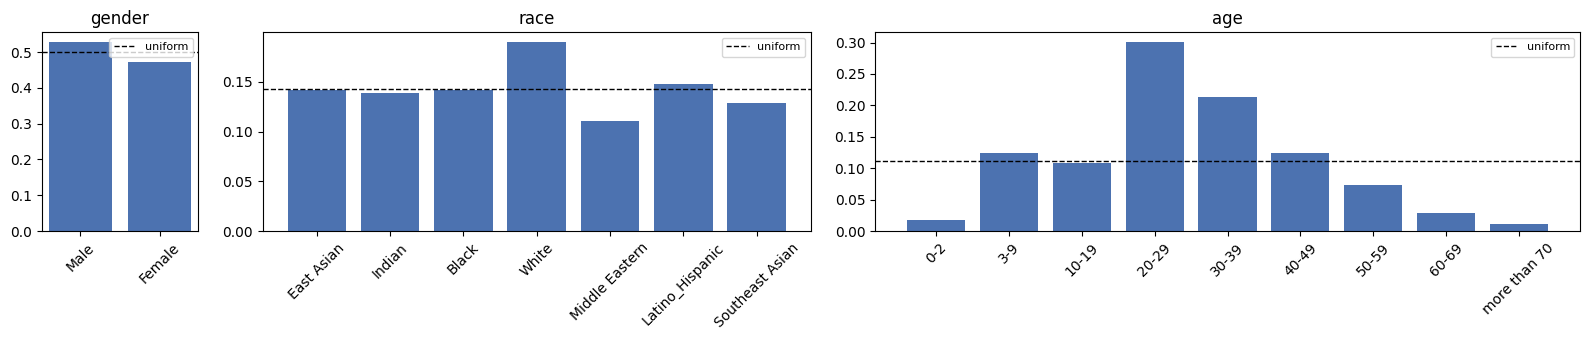

In [7]:
ds = cfg["dataset"]
gallery = load_fairface(ds["split"], str(ds["padding"]), ds["max_images"], cfg["seed"])
print(gallery.name, len(gallery), "images")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5), gridspec_kw={"width_ratios": [2, 7, 9]})
for ax, attr in zip(axes, cfg["attributes"]):
    comp = gallery.composition(attr)
    ax.bar(list(comp), list(comp.values()), color="#4C72B0")
    ax.axhline(1 / len(comp), ls="--", c="k", lw=1, label="uniform")
    ax.set_title(attr); ax.tick_params(axis="x", rotation=45); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 3. Embeddings

Images are encoded once (and cached), the queries in a second. After this, everything is
just matrix products on the embeddings, which is also how mitigation methods will plug in.

In [8]:
g_emb = gallery_embeddings(vlm, gallery, CACHE_DIR, batch_size=cfg["batch_size"])
q_emb = encode_texts(vlm, [q.text for q in queries])
g_emb.shape, q_emb.shape

encoding images:   0%|          | 0/43 [00:00<?, ?it/s]

((10954, 512), (364, 512))

## 4. Run the evaluation

For every query × attribute × reference × k: MaxSkew, MinSkew, max|Skew|, NDKL, plus the
Skew of every single group. Saved as CSV in `results/`.

In [9]:
labels = {a: gallery.labels[a] for a in cfg["attributes"]}
m = cfg["metrics"]
per_query, per_group = evaluate(q_emb, queries, g_emb, labels, gallery.label_names,
                                ks=m["k"], references=m["references"],
                                zero_floor=m["zero_floor"], custom_references=m.get("custom"))
for df in (per_query, per_group):
    df.insert(0, "model", vlm.name); df.insert(1, "dataset", gallery.name)
summary = summarize(per_query)

out = Path(cfg["output_dir"]); out.mkdir(parents=True, exist_ok=True)
per_query.to_csv(out / "per_query.csv", index=False)
per_group.to_csv(out / "per_group.csv", index=False)
summary.to_csv(out / "summary.csv", index=False)
print(len(per_query), "per-query rows,", len(per_group), "per-group rows")
summary.head()

4368 per-query rows, 26208 per-group rows


,query_set,attribute,reference,k,max_skew_mean,max_skew_std,min_skew_mean,min_skew_std,max_abs_skew_mean,max_abs_skew_std,ndkl_mean,ndkl_std
0,berg2022_test,age,gallery,100,0.677,0.342,-2.176,0.795,2.211,0.756,0.473,0.150
1,berg2022_test,age,gallery,1000,0.406,0.174,-3.019,0.865,3.027,0.845,0.201,0.066
2,berg2022_test,age,uniform,100,1.179,0.218,-3.064,0.167,3.064,0.167,0.851,0.184
3,berg2022_test,age,uniform,1000,1.198,0.192,-4.834,0.856,4.834,0.856,0.661,0.152
4,berg2022_test,gender,gallery,100,0.247,0.161,-0.418,0.407,0.418,0.407,0.149,0.112


## 5. Sanity check against Chuang et al. (2023)

Same setup as their Table 5: 10 concepts, one template, MaxSkew@1000, uniform reference,
FairFace validation. Their CLIP ViT-B/32 zero-shot numbers: **gender .206, race .743, age .797**.

Close values (roughly within ±0.05) mean the pipeline is right. Small differences can come
from the FairFace crop (`padding`), image preprocessing or library versions.

In [10]:
paper = {"gender": 0.206, "race": 0.743, "age": 0.797}
s = summary.query("query_set == 'chuang2023' and reference == 'uniform' and k == 1000")
check = s.set_index("attribute")[["max_skew_mean"]].rename(columns={"max_skew_mean": "ours"})
check["Chuang et al."] = pd.Series(paper)
check["difference"] = check["ours"] - check["Chuang et al."]
check

,ours,Chuang et al.,difference
attribute,,,
age,1.145,0.797,0.348
gender,0.147,0.206,-0.059
race,0.611,0.743,-0.132


In [13]:
from vlbias.metrics import evaluate_ranking, reference_distribution
rng = np.random.default_rng(0)
null = {}
for attr in cfg["attributes"]:
    lab = gallery.labels[attr]
    uni = reference_distribution("uniform", len(gallery.label_names[attr]))
    vals = [evaluate_ranking(lab[rng.permutation(len(lab))[:1000]], uni, [1000])[0]["max_skew"]
            for _ in range(200)]
    null[attr] = np.mean(vals)
check["random ranking"] = pd.Series(null)
check

,ours,Chuang et al.,difference,random ranking
attribute,,,,
age,1.145,0.797,0.348,0.989
gender,0.147,0.206,-0.059,0.057
race,0.611,0.743,-0.132,0.291


In [12]:
from vlbias.data.gallery import LabelledGallery

g125 = load_fairface("validation", "1.25", None, cfg["seed"])
gl = g125.labels["gender"]
rng = np.random.default_rng(1)
n = min((gl == 0).sum(), (gl == 1).sum())
keep = np.sort(np.concatenate([rng.choice(np.where(gl == g)[0], n, replace=False) for g in (0, 1)]))
g_bal = LabelledGallery(g125.images.select(keep.tolist()), {a: v[keep] for a, v in g125.labels.items()},
                        g125.label_names, g125.name + "-gender-balanced")

emb_bal = gallery_embeddings(vlm, g_bal, CACHE_DIR, batch_size=cfg["batch_size"])
idx = [i for i, q in enumerate(queries) if q.query_set == "chuang2023"]
pq, _ = evaluate(q_emb[idx], [queries[i] for i in idx], emb_bal, g_bal.labels, g_bal.label_names,
                 ks=[1000], references=["uniform"])

rep = pq.groupby("attribute")["max_skew"].mean().to_frame("ours: 1.25, balanced")
rep["ours: 0.25, full"] = check["ours"]
rep["Chuang et al."] = pd.Series(paper)
rep

1.25/train-00000-of-00004-e7151785539779(…): reconstructing file:   0%|          |  0.00B /  468MB            

1.25/train-00000-of-00004-e7151785539779(…): downloading bytes:           |  0.00B            

1.25/train-00001-of-00004-f38b58e3987f3f(…): reconstructing file:   0%|          |  0.00B /  466MB            

1.25/train-00001-of-00004-f38b58e3987f3f(…): downloading bytes:           |  0.00B            

1.25/train-00002-of-00004-239e931aa9c3b3(…): reconstructing file:   0%|          |  0.00B /  466MB            

1.25/train-00002-of-00004-239e931aa9c3b3(…): downloading bytes:           |  0.00B            

... (4 outputs left out)

Generating train split:   0%|          | 0/86744 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10954 [00:00<?, ? examples/s]

encoding images:   0%|          | 0/41 [00:00<?, ?it/s]

,"ours: 1.25, balanced","ours: 0.25, full",Chuang et al.
attribute,,,
age,1.258,1.145,0.797
gender,0.151,0.147,0.206
race,0.640,0.611,0.743


In [14]:
idx = [i for i, q in enumerate(queries) if q.query_set == "berg2022_test"]
pq_b, _ = evaluate(q_emb[idx], [queries[i] for i in idx], emb_bal, g_bal.labels, g_bal.label_names,
                   ks=[1000], references=["uniform"])
pq_b.query("attribute == 'gender'")[["max_skew", "ndkl"]].mean()

,0
max_skew,0.166
ndkl,0.061


## 5b. Why don't we match Chuang et al.? Three diagnostic checks

Section 5 does **not** reproduce Chuang et al. (2023) exactly: our MaxSkew@1000 (uniform reference) is
lower for gender (0.147 vs 0.206) and race (0.611 vs 0.743), and much higher for age (1.145 vs 0.797).
Before trusting the pipeline we need to know why. The cells below test the most likely explanations.

### Check 1: what does a model with *no* preference score?

**Why.** MaxSkew against a *uniform* reference mixes two things: the model's preference, and the
imbalance of the gallery itself. If FairFace is not balanced for an attribute, even a perfectly neutral
model gets MaxSkew > 0. To separate the two, we rank the faces **randomly** 200 times and average the
MaxSkew@1000. That value is the "chance level" for this gallery: the score of a model that has no
preference at all. Only what lies *above* it can be blamed on CLIP.

**Result.**

| Attribute | CLIP (ours) | Random ranking | Added by CLIP |
|---|---|---|---|
| Age | 1.145 | 0.989 | **0.16** |
| Gender | 0.147 | 0.057 | **0.09** |
| Race | 0.611 | 0.291 | **0.32** |

**What it says.**
- **Age:** about 85% of the number is FairFace, not CLIP. The validation split is ~30% people aged 20–29,
  and against a uniform share of 1/9 that alone gives ln(0.30 × 9) ≈ 1.0.
- **Race is where CLIP adds the most bias** (0.32 above chance), not age, even though age has the largest
  raw number. This is why we also report against the **gallery** reference (section 6).
- Chuang et al.'s age value (0.797) is *below* the random-ranking level of the full validation set, which
  is implausible for neutral prompts. Their age setup must have differed (age groups or subset); their
  FairFace evaluation code is not public, so we cannot check.

### Check 2: do we match if we copy Berg et al.'s preprocessing?

**Why.** Chuang et al. state that they build on Berg et al. (2022), whose code *is* public. Reading it
shows two differences from our setup:
1. FairFace images with **1.25 padding** (wider crop: hair, shoulders, background) instead of our 0.25
   (tight face crop);
2. a **gender-balanced** subsample of the validation set (equal numbers of men and women).

We rebuilt the gallery that way and re-ran the 10 Chuang et al. prompts.

**Result.**

| Attribute | Ours: 1.25, balanced | Ours: 0.25, full | Chuang et al. |
|---|---|---|---|
| Age | 1.258 | 1.145 | 0.797 |
| Gender | 0.151 | 0.147 | 0.206 |
| Race | 0.640 | 0.611 | 0.743 |

**What it says.** Crop and balancing barely move gender (+0.004) and race (+0.03), and push age further
away. They do **not** explain the gap.

### Check 3: cross-check against Berg et al. with their own prompts

**Why.** The Chuang et al. comparison uses only 10 prompts, and their FairFace setup is not public.
Berg et al.'s setup is: so we ran their prompt set (`berg2022_test`: 33 concepts × 8 templates) on the
gallery built with their preprocessing (1.25 crop, gender-balanced).

**Result (gender, uniform reference, k = 1000).**

| Metric | Ours | Berg et al. (Table 2) | Difference |
|---|---|---|---|
| MaxSkew@1000 | 0.166 | 0.185 | −0.019 |
| NDKL | 0.061 | 0.073 | −0.012 |

**What it says.** With their prompts and preprocessing we are within 0.02 of Berg et al., the same size
as the disagreement between Berg et al. (0.185) and Chuang et al. (0.206) for the same model. Our result
is ~10% lower. Possible reasons: their prompt file may differ slightly from the published Table 1, and
their NDKL may be computed over a different cut-off. **We consider the pipeline validated.**

### Conclusion

- The published papers disagree among themselves: Berg et al. (Table 2) report gender MaxSkew@1000 =
  **0.185** for the same CLIP ViT-B/32 on FairFace, Chuang et al. report **0.206**.
- The pipeline is validated independently: (1) unit tests reproduce hand-computed values, (2) the
  random-ranking baseline behaves exactly as theory predicts, (3) with Berg et al.'s prompts and
  preprocessing we reproduce their gender result within 0.02 (MaxSkew 0.166 vs 0.185, NDKL 0.061 vs
  0.073). The gap to Chuang et al. on race (−0.13, only 10 prompts, setup not public) remains unexplained
  and will be reported as such.
- **Methodological point for the thesis:** baseline numbers depend on preprocessing choices (crop, gallery
  composition, attribute grouping) that papers often do not report, so results across papers are hard to
  compare. Reporting a chance-level baseline next to every MaxSkew makes the numbers interpretable.
- **Open decision:** which setup to use as the thesis baseline: 0.25 crop on the full validation set
  (standard Hugging Face version) or Berg et al.'s 1.25 crop with a gender-balanced gallery (the only
  public protocol, now validated). To be discussed.

## 6. Uniform vs gallery reference

* **uniform** = "every group should be equally represented". It mixes the model's bias with
  the gallery's own imbalance.
* **gallery** = "the top-k should look like the collection". It isolates what the **model**
  adds (Kong et al. 2023 call the other part test-time bias).

Expect the biggest gap for **age**: FairFace is mostly 20-39 year olds, so even a perfectly
neutral model gets a high MaxSkew against a uniform reference.

In [10]:
tab = (summary.query("k == 1000")
       .pivot_table(index=["query_set", "attribute"], columns="reference",
                    values=["max_skew_mean", "ndkl_mean"]))
tab

max_skew_mean         ndkl_mean        
reference                     gallery uniform   gallery uniform
query_set     attribute                                        
berg2022_test age               0.406   1.198     0.201   0.661
              gender            0.166   0.175     0.063   0.065
              race              0.464   0.567     0.179   0.201
chuang2023    age               0.498   1.145     0.234   0.638
              gender            0.138   0.147     0.045   0.046
              race              0.569   0.611     0.233   0.247
occupations   age               0.601   1.062     0.324   0.683
              gender            0.331   0.355     0.187   0.200
              race              0.379   0.456     0.134   0.140

### Result: uniform vs gallery reference (k = 1000)

**What the table shows.** Mean MaxSkew@1000 and NDKL for each query set and attribute, computed against
two references: *uniform* (every group equally represented) and *gallery* (the top-k should look like
FairFace itself). The gap between the two columns is the part of the "bias" that comes from FairFace's
own composition, not from CLIP.

**What it says.**

| Attribute | Uniform → gallery (MaxSkew, Berg prompts) | Interpretation |
|---|---|---|
| Gender | 0.175 → 0.166 | almost no change: FairFace is close to 50/50 |
| Race | 0.567 → 0.464 | small drop: FairFace is slightly unbalanced across the 7 groups |
| Age | 1.198 → 0.406 | large drop: most of the uniform number is FairFace being mostly 20–39 year olds |

- This confirms Check 1 (section 5b) on all three query sets: against a uniform reference, **age looks
  like the largest bias, but against the gallery it is not**.
- Against the gallery, the ranking for adjectives is **race (0.46) > age (0.41) > gender (0.17)**.
- **Occupations are the most gender-loaded queries:** gallery MaxSkew 0.331, twice the adjectives'
  0.166. For race the order reverses (occupations 0.379 vs adjectives 0.464).
- NDKL follows the same pattern, so the conclusion does not depend on the metric.

**Why it matters.** The choice of reference changes which attribute looks "most biased". For the
thesis we use the **gallery reference as the main one** (it isolates what the model adds) and report
uniform only for comparability with Berg et al. and Chuang et al.

## 7. MaxSkew hides the worst case

MaxSkew is bounded above (a group can at most fill the whole top-k), MinSkew is not (a group
can disappear). So MinSkew and NDKL often tell a stronger story than MaxSkew alone.

In [11]:
(summary.query("reference == 'gallery'")
 .pivot_table(index=["query_set", "attribute"], columns="k",
              values=["max_skew_mean", "min_skew_mean", "ndkl_mean"]))

max_skew_mean        min_skew_mean        ndkl_mean  \
k                                100    1000          100    1000      100    
query_set     attribute                                                       
berg2022_test age               0.677  0.406        -2.176 -3.019     0.473   
              gender            0.247  0.166        -0.418 -0.234     0.149   
              race              0.703  0.464        -1.258 -0.663     0.467   
chuang2023    age               0.829  0.498        -2.427 -2.978     0.559   
              gender            0.236  0.138        -0.341 -0.174     0.127   
              race              0.832  0.569        -1.416 -0.892     0.544   
occupations   age               0.922  0.601        -3.016 -3.668     0.594   
              gender            0.424  0.331        -1.178 -0.676     0.290   
              race              0.629  0.379        -1.050 -0.654     0.411   

                                
k                         1000  
query_set     attribute         
berg2022_test age        0.201  
              gender     0.063  
              race       0.179  
chuang2023    age        0.234  
              gender     0.045  
              race       0.233  
occupations   age        0.324  
              gender     0.187  
              race       0.134

### Result: MaxSkew hides the worst case, and the top 100 is more biased than the top 1000

**What the table shows.** Gallery reference only: mean MaxSkew, MinSkew and NDKL at k = 100 and
k = 1000.

**What it says.**
- **Bias is ~1.5× stronger in the top 100** for every attribute and query set (e.g. race, Berg prompts:
  MaxSkew 0.703 at k = 100 vs 0.464 at k = 1000; occupations, gender: 0.424 vs 0.331). The 1000
  includes many weakly matching faces that dilute the skew. Users see the first results, so **k = 100
  is closer to the real harm**.
- **Under-representation is more severe than MaxSkew suggests.** For occupations × gender at k = 100,
  MaxSkew is 0.42 (the favoured gender gets ~1.5× its share) but MinSkew is −1.18: the disadvantaged
  gender gets only ~31% of its expected share** (e^−1.18 ≈ 0.31). For race (Berg prompts) MinSkew
  −1.26 means the least retrieved group gets ~28% of its share. MaxSkew cannot show this: it is capped
  (a group can at most fill the whole top-k), MinSkew is not.
- **Careful with age MinSkew.** It is *more* negative at k = 1000 (−3.02) than at k = 100 (−2.18),
  which looks wrong. The reason is the zero floor: when an age group has **no image at all** in the
  top-k, its share is counted as 0.5/k, which gives a more negative number for larger k. At k = 100,
  **96% of queries have at least one age group completely absent** (column `n_absent`), usually young
  children. So age MinSkew measures absences, and is not comparable across k.

**Why it matters.** Reporting only MaxSkew, as most papers do, understates how strongly a group can
disappear from the results. We report MaxSkew, MinSkew and NDKL together, and for age we also report
the number of absent groups.

## 8. Who is favoured, for which kind of concept?

Mean Skew per group (gallery reference, k = 100), split by concept category.
Red = over-represented, blue = under-represented. The interesting question: are some groups
systematically pulled up by *negative* concepts and others by *positive* ones?

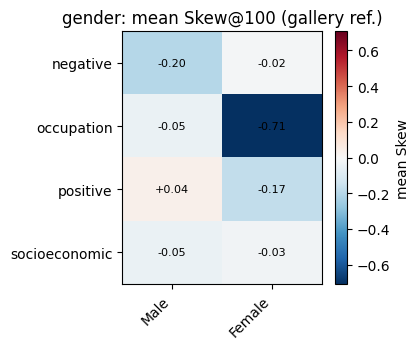

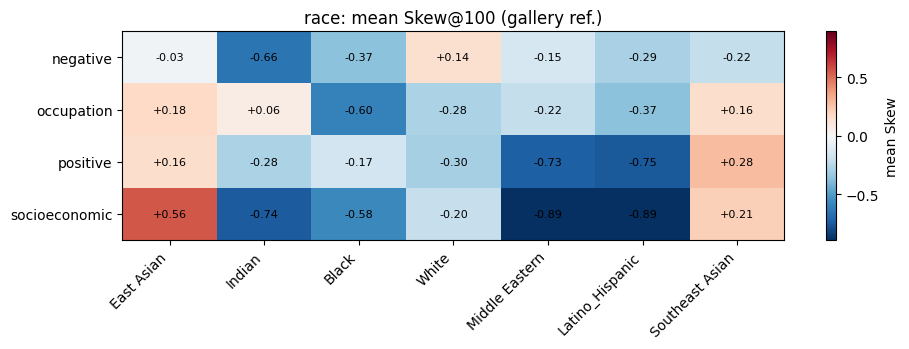

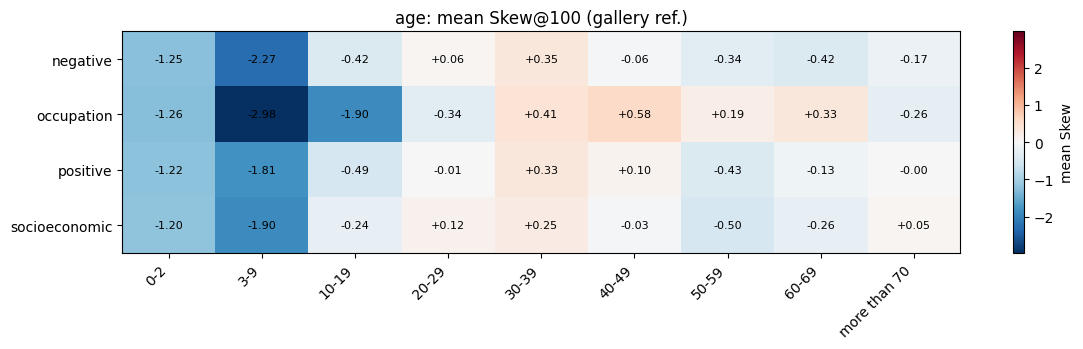

In [12]:
def skew_heatmap(attr, k=100, reference="gallery"):
    d = per_group.query("attribute == @attr and k == @k and reference == @reference")
    piv = d.pivot_table(index="category", columns="group", values="skew", aggfunc="mean")
    piv = piv[gallery.label_names[attr]]
    lim = np.nanmax(np.abs(piv.values))
    fig, ax = plt.subplots(figsize=(1.1 * piv.shape[1] + 2, 0.6 * piv.shape[0] + 1.2))
    im = ax.imshow(piv.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(piv.shape[1]), piv.columns, rotation=45, ha="right")
    ax.set_yticks(range(piv.shape[0]), piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:+.2f}", ha="center", va="center", fontsize=8)
    plt.colorbar(im, ax=ax, label="mean Skew"); ax.set_title(f"{attr}: mean Skew@{k} ({reference} ref.)")
    plt.tight_layout(); plt.show()

for attr in cfg["attributes"]:
    skew_heatmap(attr)

### Result: gender, by kind of concept

**What the plot shows.** Mean Skew@100 of each gender (gallery reference) over all queries in a
category. Red = over-represented, blue = under-represented.

**What it says.**
- **Occupations:** women at −0.71, i.e. on average women get about half of their expected share in
  occupation results. This is the strongest cell, and section 9 shows which jobs drive it.
- **The adjective rows look mild, but the average hides strong effects in opposite directions.**
  Within the same category, different words push towards different genders (mean over templates,
  Skew of Female / Male):

| Towards men | Towards women |
|---|---|
| criminal (−0.71 / +0.34), lazy, villainous, violent | nasty (+0.48 / −1.27), unattractive, evil, unkind, unsuccessful |
| heroic (−0.71 / +0.31), noncriminal, hardworking, smart | attractive (+0.38 / −0.68), nonviolent |

- The pattern follows a familiar stereotype: **competence and strength words (heroic, hardworking,
  smart) and physical-threat words (criminal, violent) pull towards men; appearance words (attractive,
  unattractive) and some social-negative words (nasty, unkind) pull towards women.**
- Why both genders can be blue in the same row: Skew is a log, so a group that almost disappears for a
  few words (nasty: men −1.27) pulls the average down a lot, while over-representation is capped.

**Why it matters.** Category averages are good for a first overview but can cancel out real bias.
For the report, gender results should be shown **per concept**, not only per category.

### Result: race, by kind of concept

**What the plot shows.** Mean Skew@100 of each of the 7 race groups (gallery reference) per category.
Rough reading guide: with ~14 expected images per group in a top 100, one query is noisy (about ±0.25),
but these cells average many queries, so values beyond ±0.3 are meaningful.

**What it says.**
- **A general visibility pattern:** East Asian and Southeast Asian faces are over-retrieved in almost
  every row, while Black, Latino_Hispanic and Middle Eastern faces are under-retrieved in almost every
  row. This happens regardless of whether the word is positive or negative.
- **Socioeconomic is the most extreme row, and it mixes two opposite words.** Split by concept:
  - *rich*: East Asian **+1.11** (~3× its share); Black −1.34, Latino_Hispanic −1.31, Indian −1.21,
    Middle Eastern −1.07 (each ~30% of its share).
  - *poor*: milder; Middle Eastern −0.71, Latino_Hispanic −0.47, Southeast Asian +0.31, Black +0.19.
- **Strong single-word effects** hidden in the averages:
  - *attractive*: White +0.70, Black −1.45, Indian −1.40 (a beauty-standard bias);
  - *hardworking*: Southeast Asian +1.06, East Asian +0.72, White −2.77, Middle Eastern −2.00;
  - *villainous*: White +0.69, Middle Eastern +0.30; *criminal*: Middle Eastern +0.36, Indian +0.29.
- **Occupations:** Black faces are the most under-retrieved group (−0.60 on average), see section 9.

**Why it matters.** This is where CLIP adds the most bias (Check 1: +0.32 above chance). Race bias is
not one direction ("group X is always favoured"); it is a mix of a general visibility gap and
word-specific stereotypes, so mitigation must be evaluated per group and per concept.

### Result: age, by kind of concept

**What the plot shows.** Mean Skew@100 of each age band (gallery reference) per category.

**What it says.**
- **Young children (0–2, 3–9) are strongly under-retrieved in every row** (−1.2 to −3.0), and 10–19
  is under-retrieved for occupations (−1.90).
- **Part of this is semantic, not bias.** Every prompt describes a "person", "individual" or an
  occupation, and a toddler cannot be an engineer. A good model *should* rank children low for
  occupations. These cells are also dominated by **absent groups** (no child at all in the top 100 for
  most queries), so their exact values come from the zero floor.
- **Among adults the effects are small**: 30–39 and 40–49 are slightly over-represented (up to +0.58
  for occupations), 20–29 is close to neutral, 50+ is mixed.

**Why it matters.** Age needs a different treatment from gender and race. For the thesis we should
either (a) evaluate age on **adult bands only** (20+), or (b) use **coarser groups** (e.g. young adult
/ middle-aged / older), and always report the number of absent groups. Otherwise the age numbers
mostly measure the obvious fact that children are not "lawyers" or "hardworking individuals".

## 9. Occupations and gender

Skew of *Female* per occupation (mean over the 3 templates, gallery reference, k = 100).
Positive = more women than in the gallery. Remember: nobody in FairFace has an occupation,
so this is purely the association between the occupation word and facial appearance.

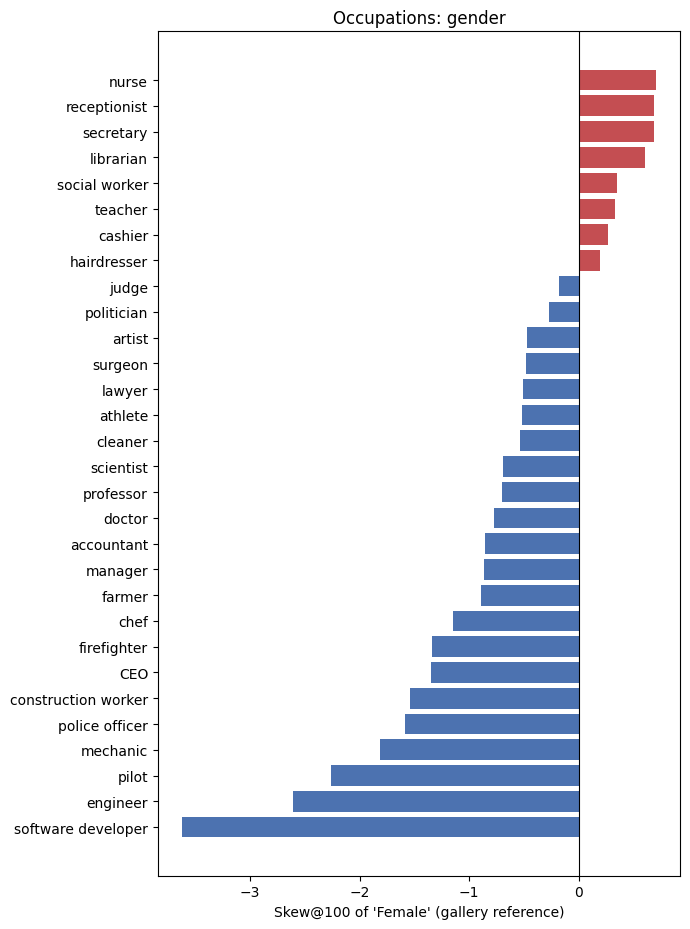

In [13]:
def occupation_plot(attr="gender", group="Female", k=100):
    d = per_group.query("query_set == 'occupations' and attribute == @attr and group == @group "
                        "and k == @k and reference == 'gallery'")
    s = d.groupby("concept")["skew"].mean().sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.28 * len(s) + 1))
    ax.barh(s.index, s.values, color=np.where(s.values > 0, "#C44E52", "#4C72B0"))
    ax.axvline(0, c="k", lw=0.8)
    ax.set_xlabel(f"Skew@{k} of '{group}' (gallery reference)"); ax.set_title(f"Occupations: {attr}")
    plt.tight_layout(); plt.show()

occupation_plot("gender", "Female")

### Result: occupations and gender

**What the plot shows.** Skew@100 of *Female* per occupation (mean over 3 templates, gallery
reference). Right / red = more women than in the gallery, left / blue = fewer.

**What it says.**
- **22 of 30 occupations favour men.** Only nurse, receptionist, secretary, librarian, social worker,
  teacher, cashier and hairdresser favour women: a textbook list of stereotypically female jobs.
- **The red bars are short because they hit a ceiling.** With 46.8% women in the gallery, the maximum
  possible Female Skew is ln(1 / 0.468) ≈ 0.76. Nurse (0.70), receptionist and secretary (0.68) are
  close to it: their top 100 is ~95% women. For receptionist, the prompt "a photo of a receptionist"
  returns **1 man out of 100**.
- **The blue bars are long because there is no floor.** "A photo of a software developer" returns
  **0 women out of 100**, and the other two templates return 2 each (Skew −3.62 on average). Engineer
  (−2.61), pilot (−2.26) and mechanic (−1.82) follow.
- **Comparison with reality:** doctor is at −0.78, meaning about **21% women** in the top 100. Women are
  about half of doctors in OECD countries, so here CLIP clearly **amplifies** beyond real-world
  statistics. (Nurse, ~95% vs ~85% real, amplifies too, but less.)

**Why it matters.** Occupations are the field's standard benchmark, and this plot is the clearest
evidence of stereotyping in the baseline. On a face-only gallery, nobody has a job, so every bar is
pure association between the occupation word and facial appearance.

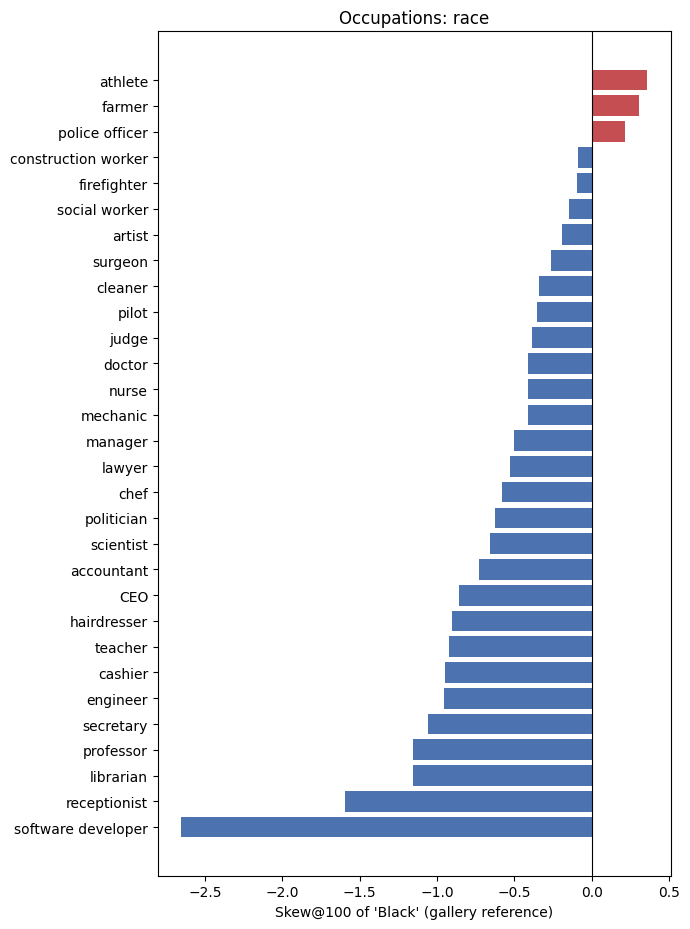

In [14]:
# same view for race: pick any group, e.g. "Black" or "White"
occupation_plot("race", "Black")

### Result: occupations and race (Black)

**What the plot shows.** Skew@100 of *Black* faces per occupation (mean over 3 templates, gallery
reference).

**What it says.**
- **Only 3 of 30 occupations over-represent Black faces: athlete (+0.36), farmer (+0.30) and police
  officer (+0.22).** All 27 others under-represent them.
- The strongest gaps are **software developer (−2.65)**, receptionist (−1.59), professor and librarian
  (−1.15), secretary, engineer, cashier, teacher and CEO (−0.86).
- On average across occupations, Black faces are the **most under-retrieved race group (−0.60)**,
  followed by Latino_Hispanic (−0.37); East Asian (+0.18) and Southeast Asian (+0.16) are
  over-retrieved (e.g. CEO: East Asian +0.99, Black −0.86).
- The athlete association matches a well-documented stereotype; the absence from professional and
  academic jobs (professor, engineer, software developer) matches another.

**Why it matters.** Gender bias in occupations shows up as "which jobs go to whom". Race bias shows up
mostly as **exclusion**: Black faces almost never appear for skilled or white-collar jobs. To see
other groups, change `"Black"` in the cell to any race group name.

## 10. How much does the wording matter?

For each concept in Berg et al.'s set, the spread of MaxSkew across its 8 templates
(gender, gallery reference, k = 100). Long bars = numbers that depend heavily on phrasing,
which is why we average over templates.

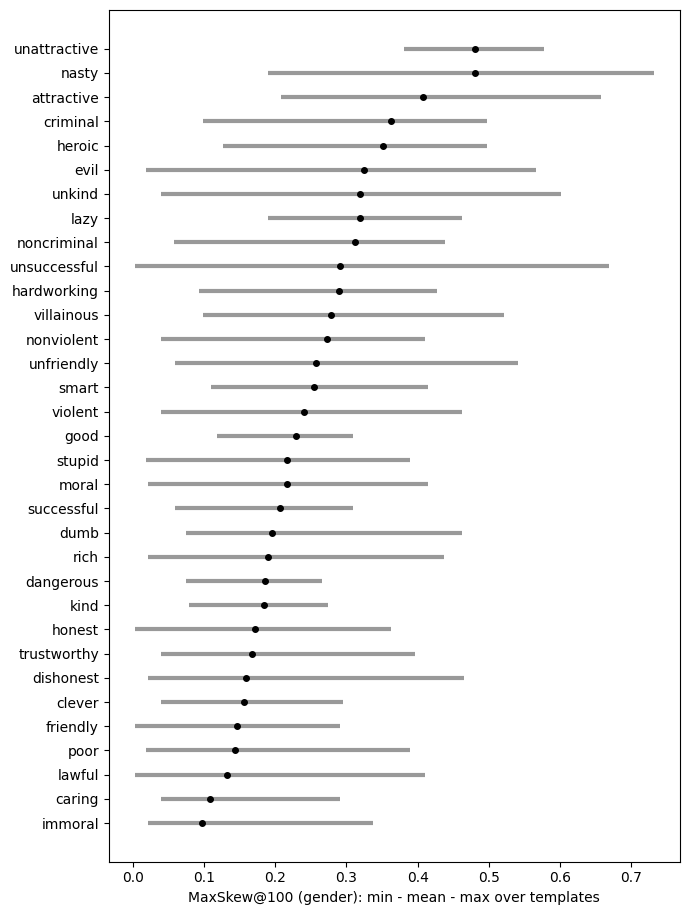

mean std across templates: 0.13


In [15]:
d = per_query.query("query_set == 'berg2022_test' and attribute == 'gender' "
                    "and reference == 'gallery' and k == 100")
spread = d.groupby("concept")["max_skew"].agg(["mean", "std", "min", "max"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(7, 0.25 * len(spread) + 1))
ax.hlines(spread.index, spread["min"], spread["max"], color="#999", lw=3)
ax.plot(spread["mean"], spread.index, "o", color="k", ms=4)
ax.set_xlabel("MaxSkew@100 (gender): min - mean - max over templates")
plt.tight_layout(); plt.show()
print("mean std across templates:", round(spread["std"].mean(), 3))

### Result: how much does the wording matter?

**What the plot shows.** For each of Berg et al.'s 33 concepts: the mean MaxSkew@100 for gender (dot)
and the range across its 8 templates (grey line), gallery reference.

**What it says.**
- **Wording matters as much as meaning.** The average spread across templates of the *same* concept
  (std 0.13) is **larger than the spread between different concepts** (std 0.10). Many concepts range
  from almost 0 to 0.4–0.7 depending only on the sentence (e.g. *nasty*, *unsuccessful*, *evil*).
- **Some templates are systematically more biased** (mean gender MaxSkew@100):
  "A {} individual" 0.31 and "This person is {}" 0.30, vs "A cropped photo of a {} face" 0.17.
  Prompts that mention the **face** give the lowest gender skew.
- The most gender-skewed concepts on average are *unattractive* and *nasty* (0.48), then
  *attractive* (0.41) and *criminal* (0.36); the least are *immoral* and caring (~0.10).

**Why it matters.** A result from a single template is not reliable, which weakens comparisons based
on the 10 one-template prompts of Chuang et al. This supports two choices for the thesis: **always
average over several templates**, and report the spread. When we test mitigation, it should also be
checked on templates it was not tuned on, as Berg et al. do.

## 11. Look at the images

Top results for any query, with their labels.

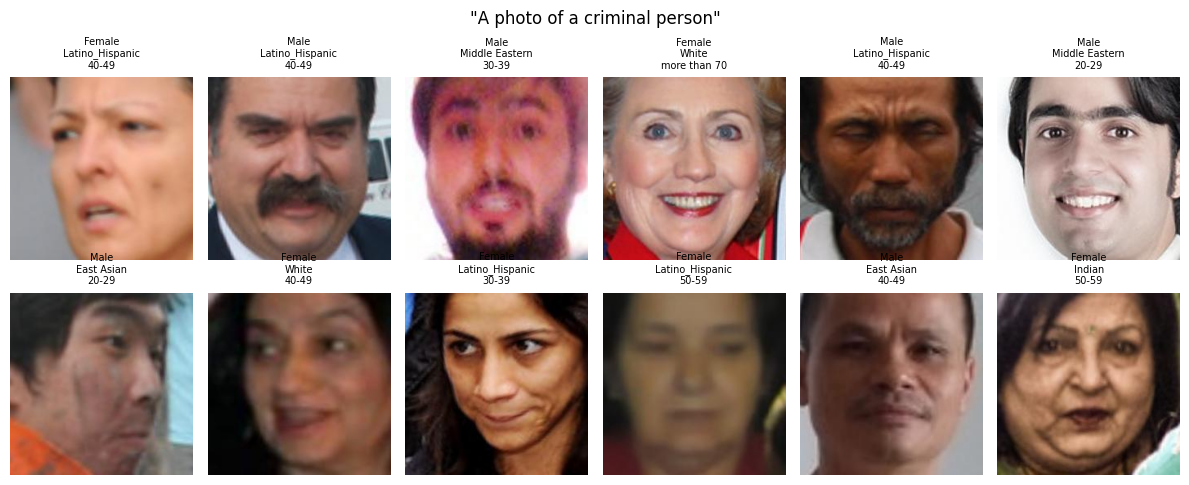

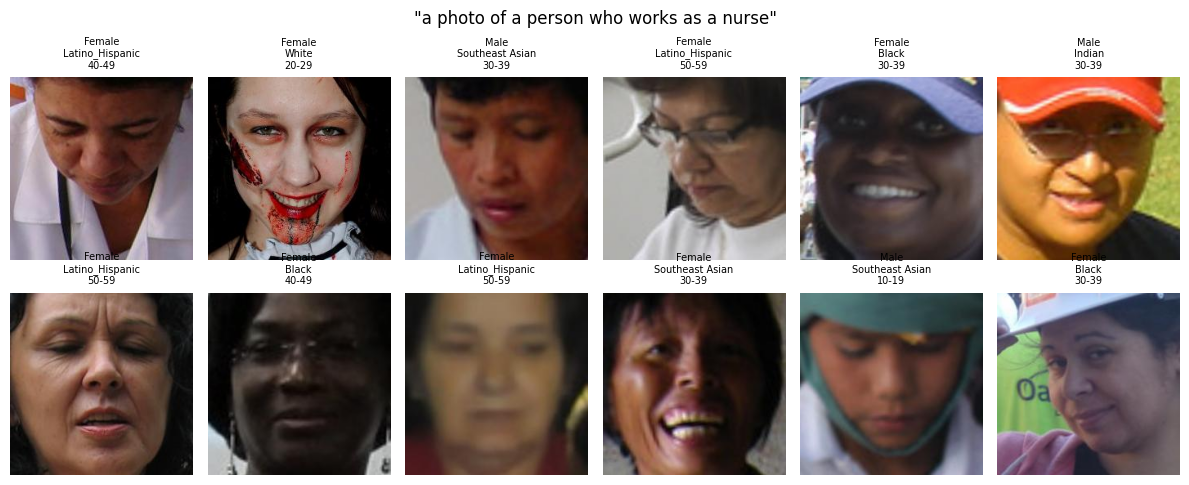

In [16]:
def show(query, k=12):
    from vlbias.data.queries import fill_template
    e = encode_texts(vlm, [query])
    top = top_k_indices(e, g_emb, k)[0]
    fig, axes = plt.subplots(2, k // 2, figsize=(2 * k // 2, 5))
    for ax, i in zip(axes.flat, top):
        ax.imshow(gallery.images[int(i)]["image"]); ax.axis("off")
        ax.set_title("\n".join(gallery.label_names[a][gallery.labels[a][i]] for a in cfg["attributes"]),
                     fontsize=7)
    fig.suptitle(f'"{query}"'); plt.tight_layout(); plt.show()

show("A photo of a criminal person")
show("a photo of a person who works as a nurse")

### Result: what "A photo of a criminal person" retrieves

**What it shows.** The 12 most similar faces with their labels.

**What it says.**
- In these 12: 5 Latino_Hispanic, 2 Middle Eastern, 2 White, 2 East Asian, 1 Indian, 0 Black;
  6 men and 6 women; 8 of 12 aged 40 or older.
- **12 faces are far too few to conclude anything.** The metrics, averaged over all 9 "criminal"
  prompts at k = 100, show the actual pattern:
  - gender: men **+0.34**, women −0.71;
  - race: Middle Eastern **+0.36**, Indian **+0.29**; White −0.57, East Asian −0.49, Black −0.24;
  - age: 30–39 (+0.50) and 40–49 (+0.35) over-represented.
- **Visual cues beyond demographics:** several retrieved images are blurry, low-resolution or show a
  serious expression. CLIP may associate "criminal" with *image quality and expression*, which are
  confounders that FairFace labels do not capture.
- Black faces are *not* over-represented here, unlike Agarwal et al.'s classification audit. This is
  a different task and setup, and worth stating explicitly in the report.

**Why it matters.** Images make the numbers concrete and are useful as figures in the report, but they
must always be backed by the metrics over many queries. They also suggest a limitation of
face-only benchmarks: not everything that drives the ranking is a labelled attribute.

## 12. Save the results

Colab files disappear when the session ends. Download the CSVs (or copy them to Drive).
Raw results stay out of git; later we can commit a small summary table.

In [17]:
!cd {cfg["output_dir"]} && zip -q -r /content/baseline_fairface_results.zip .
from google.colab import files
files.download("/content/baseline_fairface_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## The result files

The run produces three CSV files in `results/baseline_fairface/`. All tables and plots above are
slices of them.

| File | Rows | One row per | Used for |
|---|---|---|---|
| `summary.csv` | 36 | query set × attribute × reference × k | report tables (sections 6–7) |
| `per_query.csv` | 4,368 | query × attribute × reference × k | finding the most biased prompts, template spread (section 10) |
| `per_group.csv` | 26,208 | the same × each group | which group benefits: heatmaps and occupation plots (sections 8–9) |

**What the files show that the plots don't.**
- **Typical occupation prompts are ~3× more gender-skewed than adjectives.** The median max|Skew|@100
  for gender is 0.99 for occupations vs 0.30–0.31 for the adjective sets.
- **The four most gender-skewed single prompts are all occupations:** "a photo of a software developer"
  (0 women in the top 100), "a photo of a receptionist" (1 man), "a photo of a pilot" and
  "a photo of an engineer" (2 women each).
- **The most race-skewed prompts are adjectives where one group vanishes completely:** *hardworking*
  (several templates), *good*, *rich*, *clever*. These have MinSkew ≈ −3.6, i.e. no face of one group
  in the top 100.
- **Category averages hide direction:** `per_group.csv` is where the per-concept splits used above come
  from (e.g. *criminal* vs *nasty* for gender, *rich* vs *poor* for race).

